   # Do variability classes differ in amplitude?
   Main sample (G <= 17, classifier score >= 0.5) from notebook 03. Amplitude measure: trimmed range in the G band, log10-transformed.

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

c = pd.read_csv("../data/processed/classified_sample_flagged.csv")
m = c[c["main_sample"]].copy()
m = m[m["best_class_name"] != "CV"]          # CV has only 3 stars after the cuts

print(len(m), "stars (CV excluded)")
print("non-positive trimmed ranges:", (m["trimmed_range_mag_g_fov"] <= 0).sum())

m["log_amp"] = np.log10(m["trimmed_range_mag_g_fov"])

summary = m.groupby("best_class_name")["log_amp"].agg(["size", "mean", "std", "median"]).round(3)
print(summary)

2079 stars (CV excluded)
non-positive trimmed ranges: 0
                 size   mean    std  median
best_class_name                            
CEP                83 -0.294  0.167  -0.292
DSCT|GDOR|SXPHE   425 -1.575  0.240  -1.629
ECL               138 -0.643  0.361  -0.580
LPV               427 -0.581  0.346  -0.659
RR                231 -0.231  0.165  -0.215
RS                309 -0.982  0.178  -0.991
S                 160 -0.271  0.116  -0.273
SOLAR_LIKE        306 -1.580  0.137  -1.596


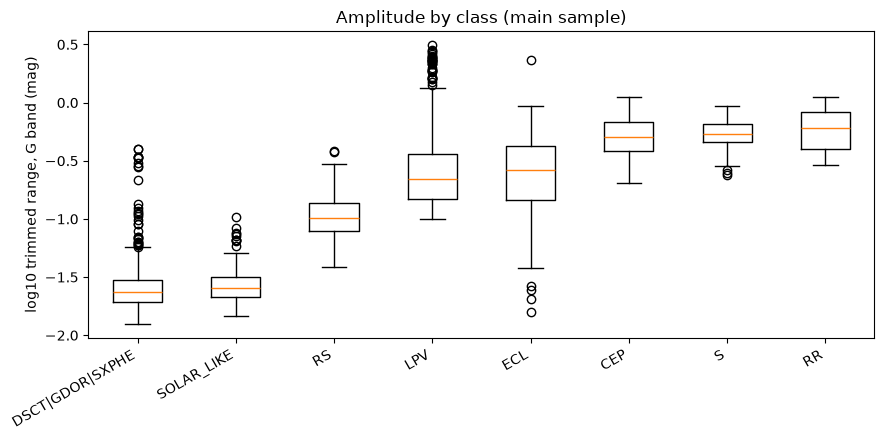

In [2]:
order = summary.sort_values("median").index
data = [m.loc[m["best_class_name"] == k, "log_amp"] for k in order]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot(data)
ax.set_xticks(range(1, len(order) + 1))
ax.set_xticklabels(order, rotation=30, ha="right")
ax.set_ylabel("log10 trimmed range, G band (mag)")
ax.set_title("Amplitude by class (main sample)")
plt.tight_layout()
plt.show()

In [3]:
import statsmodels.api as sm
from statsmodels.formula.api import ols
from stats_toolkit import one_way_anova

order = list(summary.index)
glist = [m.loc[m["best_class_name"] == k, "log_amp"].to_numpy() for k in order]

res = one_way_anova(glist)
for k, v in res.items():
    print(k, ":", v)

allv = np.concatenate(glist)
print()
print("SST computed directly :", np.sum((allv - allv.mean()) ** 2))
print("SSB + SSW             :", res["SSB"] + res["SSW"])

print()
f_sp, p_sp = stats.f_oneway(*glist)
print("scipy f_oneway: F =", f_sp, "| p =", p_sp)

fit = ols("log_amp ~ C(best_class_name)", data=m).fit()
print()
print(sm.stats.anova_lm(fit, typ=1))

SSB : 586.174730095849
SSW : 119.55317829106491
SST : 705.7279083869139
df_between : 7
df_within : 2071
MSB : 83.73924715654985
MSW : 0.05772727102417427
F : 1450.6011746420963
p : 0.0
eta2 : 0.8305959324120704

SST computed directly : 705.7279083869137
SSB + SSW             : 705.7279083869139

scipy f_oneway: F = 1450.601174642096 | p = 0.0

                        df      sum_sq    mean_sq            F  PR(>F)
C(best_class_name)     7.0  586.174730  83.739247  1450.601175     0.0
Residual            2071.0  119.553178   0.057727          NaN     NaN


Levene (median-centred): W = 38.26344036169509 | p = 9.486906455773467e-51
largest / smallest group variance: 9.7

Welch ANOVA: F = 2983.91831304015 | df = (7.0, np.float64(629.12764711769)) | p = 0.0
Kruskal-Wallis: H = 1698.5809826187951 | p = 0.0

residual skewness: 1.19 | excess kurtosis: 4.668


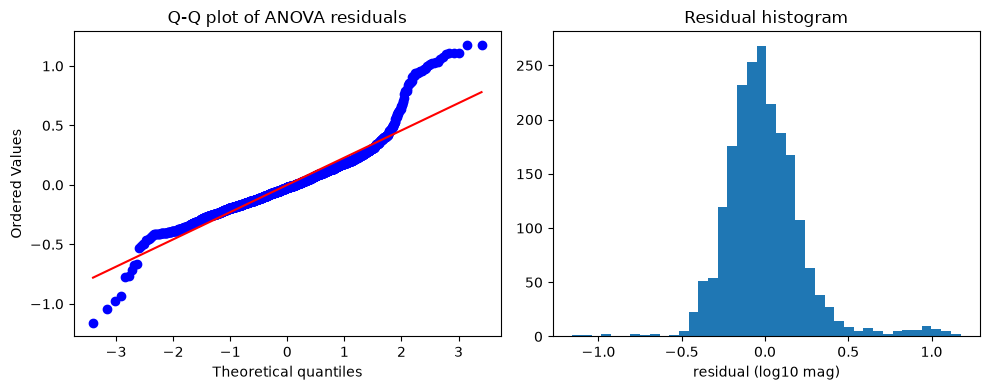

In [4]:
from statsmodels.stats.oneway import anova_oneway

# 1. equal variances
lev = stats.levene(*glist, center="median")
print("Levene (median-centred): W =", lev.statistic, "| p =", lev.pvalue)
print("largest / smallest group variance:",
      round(max(np.var(g, ddof=1) for g in glist) / min(np.var(g, ddof=1) for g in glist), 2))

# 2. alternatives that do not assume equal variances
w = anova_oneway(glist, use_var="unequal")
print()
print("Welch ANOVA: F =", w.statistic, "| df =", w.df, "| p =", w.pvalue)

kw = stats.kruskal(*glist)
print("Kruskal-Wallis: H =", kw.statistic, "| p =", kw.pvalue)

# 3. normality of residuals
resid = fit.resid
print()
print("residual skewness:", round(stats.skew(resid), 3),
      "| excess kurtosis:", round(stats.kurtosis(resid), 3))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
stats.probplot(resid, dist="norm", plot=ax[0])
ax[0].set_title("Q-Q plot of ANOVA residuals")
ax[1].hist(resid, bins=40)
ax[1].set_title("Residual histogram")
ax[1].set_xlabel("residual (log10 mag)")
plt.tight_layout()
plt.show()

In [5]:
from stats_toolkit import games_howell

gh = pd.DataFrame(games_howell(glist, order))
gh["amplitude ratio"] = 10 ** gh["diff"]          # class i / class j, since the data are log10
gh["significant (p<0.05)"] = gh["p"] < 0.05

# check: t and df must equal Welch's t-test for the same pair (the p-values differ, because of the adjustment)
chk = stats.ttest_ind(glist[0], glist[1], equal_var=False)
print("pair:", order[0], "vs", order[1])
print("mine  : t =", gh.loc[0, "t"], "| df =", gh.loc[0, "df"])
print("scipy : t =", chk.statistic, "| df =", chk.df)
print()

print(gh[["group_i", "group_j", "diff", "amplitude ratio", "p", "significant (p<0.05)"]].round(4).to_string())
print()
print("pairs NOT significant:", (~gh["significant (p<0.05)"]).sum(), "of", len(gh))

pair: CEP vs DSCT|GDOR|SXPHE
mine  : t = 59.08594909348712 | df = 157.26893689064028
scipy : t = 59.08594909348712 | df = 157.26893689064028

            group_i          group_j    diff  amplitude ratio       p  significant (p<0.05)
0               CEP  DSCT|GDOR|SXPHE  1.2808          19.0907  0.0000                  True
1               CEP              ECL  0.3488           2.2326  0.0000                  True
2               CEP              LPV  0.2867           1.9349  0.0000                  True
3               CEP               RR -0.0631           0.8648  0.0667                 False
4               CEP               RS  0.6885           4.8804  0.0000                  True
5               CEP                S -0.0233           0.9477  0.9466                 False
6               CEP       SOLAR_LIKE  1.2860          19.3187  0.0000                  True
7   DSCT|GDOR|SXPHE              ECL -0.9320           0.1169  0.0000                  True
8   DSCT|GDOR|SXPHE           

In [6]:
from statsmodels.stats.oneway import anova_oneway
from stats_toolkit import one_way_anova, games_howell

def anova_summary(df, label):
    df = df[df["best_class_name"] != "CV"].copy()
    n_before = len(df)
    df = df[df["trimmed_range_mag_g_fov"] > 0].copy()       # logs need positive values
    df["log_amp"] = np.log10(df["trimmed_range_mag_g_fov"])
    names = sorted(df["best_class_name"].unique())
    gl = [df.loc[df["best_class_name"] == k, "log_amp"].to_numpy() for k in names]
    a = one_way_anova(gl)
    w = anova_oneway(gl, use_var="unequal")
    g = pd.DataFrame(games_howell(gl, names))
    return {"sample": label, "stars": len(df), "dropped (range<=0)": n_before - len(df),
            "smallest class": min(len(x) for x in gl),
            "eta2": a["eta2"], "classical F": a["F"], "Welch F": w.statistic,
            "pairs not significant (of 28)": int((g["p"] >= 0.05).sum())}

G = c["phot_g_mean_mag"]
samples = {
    "G<=17, score>=0.5 (main)": c[(G <= 17) & c["score_ge_05"]],
    "G<=18, score>=0.5":        c[(G <= 18) & c["score_ge_05"]],
    "G<=17, score>=0.3":        c[(G <= 17) & c["score_ge_03"]],
    "G<=17, score>=0.7":        c[(G <= 17) & c["score_ge_07"]],
}

pd.DataFrame([anova_summary(d, k) for k, d in samples.items()]).round(3)

,sample,stars,dropped (range<=0),smallest class,eta2,classical F,Welch F,pairs not significant (of 28)
0,"G<=17, score>=0.5 (main)",2079,0,83,0.831,1450.601,2983.918,5
1,"G<=18, score>=0.5",2802,0,102,0.826,1899.584,3319.532,5
2,"G<=17, score>=0.3",3014,0,105,0.847,2376.570,3757.042,3
3,"G<=17, score>=0.7",1196,0,47,0.786,624.988,1269.214,4


In [7]:
from stats_toolkit import chi_square_independence

mm = m.dropna(subset=["bp_rp"]).copy()
print(len(m) - len(mm), "stars dropped for missing bp_rp;", len(mm), "remain")

mm["colour_band"] = pd.qcut(mm["bp_rp"], 3, labels=["bluest third", "middle third", "reddest third"])
tab = pd.crosstab(mm["best_class_name"], mm["colour_band"])
print(tab)

res = chi_square_independence(tab.to_numpy())
print()
print("chi2 =", res["chi2"], "| df =", res["df"], "| p =", res["p"])
print("Cramer's V =", res["cramers_v"], "| smallest expected count =", res["min_expected"])

chi2_s, p_s, dof_s, exp_s = stats.chi2_contingency(tab.to_numpy())[:4]
print("scipy: chi2 =", chi2_s, "| df =", dof_s, "| p =", p_s)
print("scipy Cramer's V:", stats.contingency.association(tab.to_numpy(), method="cramer"))

print()
print(pd.DataFrame(res["adj_resid"], index=tab.index, columns=tab.columns).round(1))

1 stars dropped for missing bp_rp; 2078 remain
colour_band      bluest third  middle third  reddest third
best_class_name                                           
CEP                        41            22             20
DSCT|GDOR|SXPHE           400            25              0
ECL                        51            64             22
LPV                         0             0            427
RR                        161            52             18
RS                          8           219             82
S                          12           101             47
SOLAR_LIKE                 20           209             77

chi2 = 2219.6808724740768 | df = 14 | p = 0.0
Cramer's V = 0.7308150802621118 | smallest expected count = 27.640038498556304
scipy: chi2 = 2219.6808724740768 | df = 14 | p = 0.0
scipy Cramer's V: 0.7308150802621118

colour_band      bluest third  middle third  reddest third
best_class_name                                           
CEP                       3.

In [8]:
from stats_toolkit import chi_square_gof

props = tab.sum(axis=0).to_numpy() / tab.to_numpy().sum()     # overall colour mix of the sample
print("overall colour mix:", props.round(4))

rows = []
for cls, obs in tab.iterrows():
    mine = chi_square_gof(obs.to_numpy(), props)
    sp = stats.chisquare(obs.to_numpy(), f_exp=obs.sum() * props)
    rows.append({"class": cls, "n": obs.sum(), "chi2 (mine)": mine["chi2"],
                 "chi2 (scipy)": sp.statistic, "df": mine["df"], "p": mine["p"]})

g = pd.DataFrame(rows).round(4)
print(g.to_string(index=False))
print()
print("sum of the per-class chi2:", g["chi2 (mine)"].sum())
print("independence chi2        :", 2219.6808724740768)

overall colour mix: [0.3335 0.333  0.3335]
          class   n  chi2 (mine)  chi2 (scipy)  df      p
            CEP  83       9.6915        9.6915   2 0.0079
DSCT|GDOR|SXPHE 425     708.2845      708.2845   2 0.0000
            ECL 137      20.3021       20.3021   2 0.0000
            LPV 427     853.3838      853.3838   2 0.0000
             RR 231     144.8309      144.8309   2 0.0000
             RS 309     222.9606      222.9606   2 0.0000
              S 160      75.5505       75.5505   2 0.0000
     SOLAR_LIKE 306     184.6768      184.6768   2 0.0000

sum of the per-class chi2: 2219.6807
independence chi2        : 2219.6808724740768


In [9]:
from stats_toolkit import chi_square_single_variance

sigma0 = 0.20      # illustrative benchmark SD of log10 amplitude (about a factor 1.6); not a literature value
rows = []
for k, g in zip(order, glist):
    r = chi_square_single_variance(g, sigma0 ** 2)
    rows.append({"class": k, "n": r["n"], "sd": np.sqrt(r["s2"]),
                 "chi2": r["chi2"], "df": r["df"], "p": r["p"],
                 "sd CI low": np.sqrt(r["ci_var"][0]), "sd CI high": np.sqrt(r["ci_var"][1]),
                 "excess kurtosis": stats.kurtosis(g)})
print(pd.DataFrame(rows).round(3).to_string(index=False))

# self-checks
g0 = glist[0]
print()
print("chi2 when sigma0 = sample sd:", chi_square_single_variance(g0, np.var(g0, ddof=1))["chi2"], "| n-1 =", len(g0) - 1)

rng = np.random.default_rng(1)
rej = np.mean([chi_square_single_variance(rng.normal(0, sigma0, 200), sigma0 ** 2)["p"] < 0.05
               for _ in range(5000)])
print("Type I rate, normal data, n = 200:", rej)

          class   n    sd     chi2  df     p  sd CI low  sd CI high  excess kurtosis
            CEP  83 0.167   56.831  82 0.031      0.144       0.197           -0.679
DSCT|GDOR|SXPHE 425 0.240  612.232 424 0.000      0.225       0.258            8.209
            ECL 138 0.361  446.424 137 0.000      0.323       0.409            0.741
            LPV 427 0.346 1277.573 426 0.000      0.325       0.371            1.307
             RR 231 0.165  155.753 230 0.000      0.151       0.181           -1.350
             RS 309 0.178  243.543 308 0.005      0.165       0.193           -0.183
              S 160 0.116   53.439 159 0.000      0.104       0.130            0.101
     SOLAR_LIKE 306 0.137  143.034 305 0.000      0.127       0.149            2.033

chi2 when sigma0 = sample sd: 82.0 | n-1 = 82
Type I rate, normal data, n = 200: 0.0488


In [10]:
import statsmodels.api as sm
from statsmodels.formula.api import ols
from stats_toolkit import two_way_anova

t = m.copy()
t["g_band"] = np.where(t["phot_g_mean_mag"] <= 16, "G<=16", "16<G<=17")

cells = pd.crosstab(t["best_class_name"], t["g_band"])
print(cells)
print("smallest cell:", cells.to_numpy().min())

res2 = pd.DataFrame(two_way_anova(t["log_amp"], t["best_class_name"], t["g_band"])).T
print()
print(res2.round(4))

fit2 = ols("log_amp ~ C(best_class_name) * C(g_band)", data=t).fit()
print()
print(sm.stats.anova_lm(fit2, typ=2))

g_band           16<G<=17  G<=16
best_class_name                 
CEP                    26     57
DSCT|GDOR|SXPHE        18    407
ECL                    61     77
LPV                    91    336
RR                    122    109
RS                    107    202
S                     151      9
SOLAR_LIKE             55    251
smallest cell: 9

                      SS      df          F       p  partial_eta2
A (class)       490.4616     7.0  1250.7668  0.0000        0.8093
B (brightness)    0.6013     1.0    10.7338  0.0011        0.0052
A x B             3.3860     7.0     8.6348  0.0000        0.0285
residual        115.5659  2063.0        NaN     NaN           NaN

                                  sum_sq      df            F        PR(>F)
C(best_class_name)            490.461556     7.0  1250.766806  0.000000e+00
C(g_band)                       0.601291     1.0    10.733809  1.069395e-03
C(best_class_name):C(g_band)    3.385959     7.0     8.634816  1.775333e-10
Residual         